In [1]:
import sys
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
# read_ids = list(range(0, 8+1))
read_ids = [2]
plot_id = 2

In [4]:
# read
path = os.path.join(read_utils.get_data_path(), '6163622/sessions')
(file_ids, filenames,
 traces,
 continuous_behaviors,
 motion_pcs,
 motion_masks) = read_utils.get_datas(path, read_ids,
									  with_whisking=True)

# # clear nan values
for i in range(len(file_ids)):
	# mask = motion_pcs[i][0].notna().all(axis=1)
	mask = continuous_behaviors[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	motion_pcs[i][0] = motion_pcs[i][0][mask]
	motion_pcs[i][1] = motion_pcs[i][1][mask]
	continuous_behaviors[i] = continuous_behaviors[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [5]:
plot_idx = file_ids.index(plot_id)

# states = [ds[selection_bhl] for ds in states]

In [6]:
X = traces[plot_idx]

(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca([X],
												 n_pc=3)

In [7]:
np.sum(vars_expl_mans)

np.float32(0.08781316)

In [8]:
traces_manifolds_indices = [np.argsort(xloads_pca_man[0, :])[::-1] for xloads_pca_man in loads_pca_man]

traces_sorted = [t.iloc[:, t_man_idx.tolist()] for t, t_man_idx in zip(traces, traces_manifolds_indices)]

traces_manifolds_sorted = [t_man.iloc[:, t_man_idx.tolist()] for t_man, t_man_idx in zip(recos_manifold, traces_manifolds_indices)]

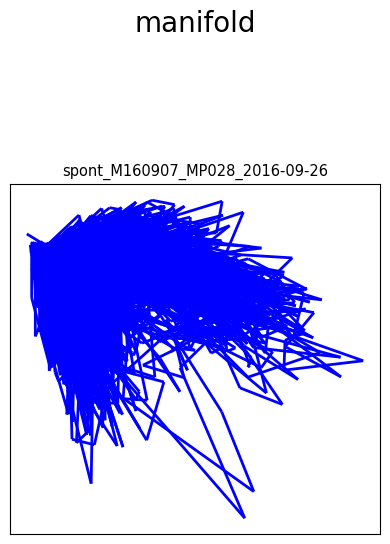

In [9]:
plot_utils.plot_manifolds(filenames,
						  modes_manifold, None,
						  title='manifold', top_space=1)

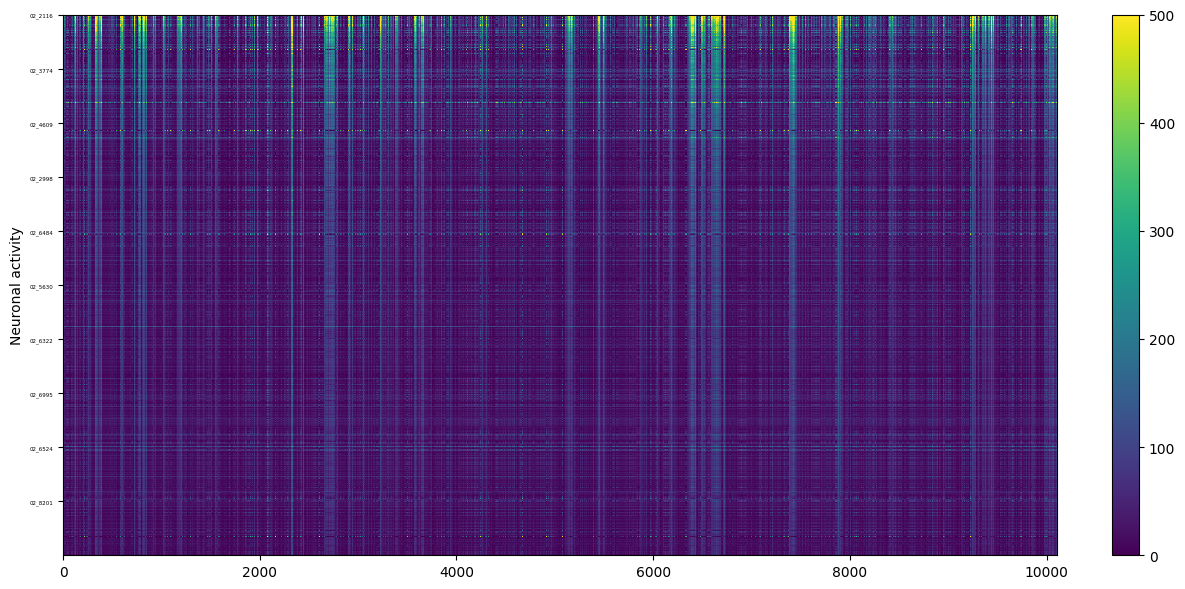

In [10]:
plot_utils.plot_heatmap_stack(traces_manifolds_sorted[plot_idx].iloc[:, :1000], None,
							  label_traces='Neuronal activity', label_behavior=None,
							  height_ratios=(0, 1),
							  zlimits_activity=(0, 500), cmap='viridis')